In [2]:

# STEP 1: IMPORT LIBRARIES AND LOAD DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("global_ecommerce_sales_.csv")

# Keep original data unchanged
raw_df = df.copy()

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Check dataset size
print("Dataset Shape:", df.shape)

# Check dataset information
print("\nDataset Information:")
df.info()


First 5 Rows:


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,2023-01-02,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,2023-01-02,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,2023-01-03,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,2023-01-03,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,2023-01-05,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


Dataset Shape: (2008, 15)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2008 entries, 0 to 2007
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2008 non-null   object 
 1   Order_Date        2008 non-null   object 
 2   Customer_Name     2008 non-null   object 
 3   Customer_Segment  2003 non-null   object 
 4   Country           2008 non-null   object 
 5   Region            2008 non-null   object 
 6   Product_Category  2004 non-null   object 
 7   Product_Name      2008 non-null   object 
 8   Quantity          2008 non-null   int64  
 9   Unit_Price        2008 non-null   float64
 10  Discount_Percent  2008 non-null   int64  
 11  Total_Sales       2008 non-null   float64
 12  Shipping_Cost     2003 non-null   float64
 13  Profit            2008 non-null   float64
 14  Payment_Method    2004 non-null   object 
dtypes: float64(4), int64(2), object(9)
memory

In [3]:

# STEP 2: EXPLORATORY DATA ANALYSIS

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Summary statistics
print("\nSummary Statistics:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check unique values
print("\nUnique Values:")
print(df.nunique())

# Explore product categories
print("\nProduct Categories:")
print(df["Product_Category"].value_counts(dropna=False))

# Explore payment methods
print("\nPayment Methods:")
print(df["Payment_Method"].value_counts(dropna=False))

# Explore customer segments
print("\nCustomer Segments:")
print(df["Customer_Segment"].value_counts(dropna=False))


Column Names:
['Order_ID', 'Order_Date', 'Customer_Name', 'Customer_Segment', 'Country', 'Region', 'Product_Category', 'Product_Name', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Shipping_Cost', 'Profit', 'Payment_Method']

Data Types:
Order_ID             object
Order_Date           object
Customer_Name        object
Customer_Segment     object
Country              object
Region               object
Product_Category     object
Product_Name         object
Quantity              int64
Unit_Price          float64
Discount_Percent      int64
Total_Sales         float64
Shipping_Cost       float64
Profit              float64
Payment_Method       object
dtype: object

Summary Statistics:


,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit
count,2008.000000,2008.000000,2008.000000,2008.000000,2003.000000,2008.000000
mean,3.557769,73.472958,8.563247,242.502435,12.912297,79.490523
std,2.701316,79.523613,7.261572,382.355009,5.219769,137.401093
min,1.000000,3.030000,0.000000,2.420000,5.520000,-11.280000
25%,2.000000,18.757500,0.000000,41.227500,9.460000,6.865000
50%,3.000000,46.440000,10.000000,113.185000,11.850000,32.915000
75%,5.000000,90.365000,15.000000,267.315000,14.940000,90.600000
max,15.000000,472.560000,30.000000,3813.980000,40.440000,1373.630000



Missing Values:
Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    5
Country             0
Region              0
Product_Category    4
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_Cost       5
Profit              0
Payment_Method      4
dtype: int64

Total Missing Values: 18

Duplicate Rows: 8

Unique Values:
Order_ID            2000
Order_Date           907
Customer_Name       1534
Customer_Segment       4
Country               20
Region                 5
Product_Category       6
Product_Name          40
Quantity              15
Unit_Price          1839
Discount_Percent       7
Total_Sales         1927
Shipping_Cost       1114
Profit              1855
Payment_Method         4
dtype: int64

Product Categories:
Product_Category
Technology                564
Office Supplies           515
Furniture                 507
Clothing & Accessories    412
NaN                         4
 te

In [4]:

# STEP 3: DATA CLEANING AND TRANSFORMATION

# Create working copy
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates().copy()

# Clean categorical text columns
text_columns = [
    "Customer_Segment",
    "Product_Category",
    "Payment_Method"
]

for col in text_columns:
    clean_df[col] = clean_df[col].str.strip()
    clean_df[col] = clean_df[col].str.title()
    clean_df[col] = clean_df[col].fillna("Unknown")

# Fill missing shipping costs with median
median_shipping = clean_df["Shipping_Cost"].median()

clean_df["Shipping_Cost"] = clean_df["Shipping_Cost"].fillna(
    median_shipping
)

# Convert order date to datetime
clean_df["Order_Date"] = pd.to_datetime(
    clean_df["Order_Date"]
)

# Extract month from order date
clean_df["Order_Month"] = (
    clean_df["Order_Date"].dt.to_period("M").astype(str)
)

# Check results after cleaning
print("Cleaned Dataset Shape:", clean_df.shape)

print("\nMissing Values After Cleaning:")
print(clean_df.isnull().sum())

print("\nDuplicate Rows After Cleaning:")
print(clean_df.duplicated().sum())

# Display cleaned dataset
display(clean_df.head())


Cleaned Dataset Shape: (2000, 16)

Missing Values After Cleaning:
Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    0
Country             0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_Cost       0
Profit              0
Payment_Method      0
Order_Month         0
dtype: int64

Duplicate Rows After Cleaning:
0


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method,Order_Month
0,ORD-11121,2023-01-02,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash On Delivery,2023-01
1,ORD-11244,2023-01-02,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash On Delivery,2023-01
2,ORD-10325,2023-01-03,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card,2023-01
3,ORD-10467,2023-01-03,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,Paypal,2023-01
4,ORD-11454,2023-01-05,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card,2023-01


In [5]:

# STEP 4: DATA ANALYSIS

# 1. Calculate total sales revenue
total_sales = clean_df["Total_Sales"].sum()

print("Total Sales Revenue:", round(total_sales, 2))

# 2. Calculate total profit
total_profit = clean_df["Profit"].sum()

print("Total Profit:", round(total_profit, 2))

# 3. Calculate sales by product category
category_sales = clean_df.groupby(
    "Product_Category"
)["Total_Sales"].sum()

category_sales = category_sales.sort_values(
    ascending=False
)

print("\nSales by Product Category:")
print(category_sales)

# 4. Find top 5 countries by revenue
country_sales = clean_df.groupby(
    "Country"
)["Total_Sales"].sum()

country_sales = country_sales.sort_values(
    ascending=False
)

print("\nTop 5 Countries by Revenue:")
print(country_sales.head(5))

# 5. Analyze monthly revenue
monthly_sales = clean_df.groupby(
    "Order_Month"
)["Total_Sales"].sum()

monthly_sales = monthly_sales.sort_index()

print("\nMonthly Sales:")
print(monthly_sales)

print("\nHighest Revenue Month:")
print(monthly_sales.idxmax())


Total Sales Revenue: 484559.34
Total Profit: 158872.32

Sales by Product Category:
Product_Category
Furniture                 253143.86
Technology                139215.10
Clothing & Accessories     68831.23
Office Supplies            22603.90
Unknown                      765.25
Name: Total_Sales, dtype: float64

Top 5 Countries by Revenue:
Country
Mexico            47217.30
Canada            45326.55
United States     41332.53
Japan             30950.19
United Kingdom    30185.46
Name: Total_Sales, dtype: float64

Monthly Sales:
Order_Month
2023-01    11275.20
2023-02    16943.67
2023-03    16056.45
2023-04    12185.00
2023-05     8218.47
2023-06    16191.61
2023-07    15667.73
2023-08    12971.07
2023-09    11989.72
2023-10    17794.60
2023-11     8475.49
2023-12    16674.44
2024-01     8015.21
2024-02    11979.60
2024-03    10550.11
2024-04    15615.06
2024-05    16594.20
2024-06     9435.15
2024-07    14937.53
2024-08     9883.83
2024-09     9636.38
2024-10    17426.05
2024-11    1

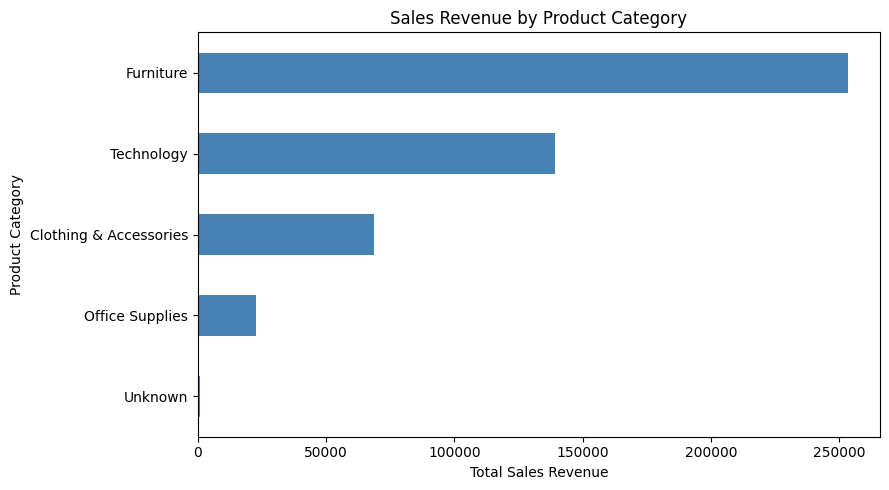

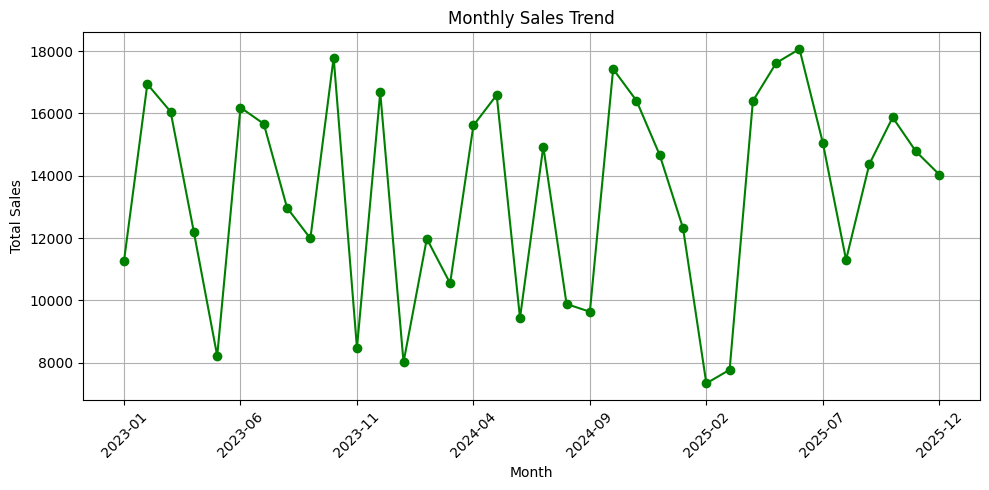

In [6]:

# VISUALIZATION 1: SALES BY PRODUCT CATEGORY

category_sales.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Sales Revenue by Product Category")
plt.xlabel("Total Sales Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


# VISUALIZATION 2: MONTHLY SALES TREND

monthly_sales.plot(
    kind="line",
    figsize=(10, 5),
    marker="o",
    color="green"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [7]:

# STEP 5: SAVE CLEANED DATASET

# Save cleaned dataset
clean_df.to_csv(
    "global_ecommerce_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

# Download cleaned dataset
from google.colab import files

files.download("global_ecommerce_sales_cleaned.csv")


Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>